# Fake Job Posting Dataset Assessment and Narrative 

**Name:** Tyra Ferguson
**Course:** ISDS 7070
**Date:** 7/21/2026

### Outline
1. Step Zero
2. Initial Assumptions
3. Data Wrangling
4. Statistical data visualizations
5. Descriptive statistics of the wrangled data
6. Conculsion

# Step Zero - Initial Set up 

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from matplotlib import pyplot
import seaborn as sns

### Load the Dataset

In [2]:
path = "../data/fake_job_postings.csv"  # download from Kaggle (see README)

In [3]:
df_jobs = pd.read_csv(path)

In [4]:
df_jobs.head(30)

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0
5,6,Accounting Clerk,"US, MD,",NaN,NaN,NaN,Job OverviewApex is an environmental consultin...,NaN,NaN,0,0,0,NaN,NaN,NaN,NaN,NaN,0
6,7,Head of Content (m/f),"DE, BE, Berlin",ANDROIDPIT,20000-28000,"Founded in 2009, the Fonpit AG rose with its i...",Your Responsibilities: Manage the English-spea...,Your Know-How: ...,Your Benefits: Being part of a fast-growing co...,0,1,1,Full-time,Mid-Senior level,Master's Degree,Online Media,Management,0
7,8,Lead Guest Service Specialist,"US, CA, San Francisco",NaN,NaN,Airenvy’s mission is to provide lucrative yet ...,Who is Airenvy?Hey there! We are seasoned entr...,"Experience with CRM software, live chat, and p...",Competitive Pay. You'll be able to eat steak e...,0,1,1,NaN,NaN,NaN,NaN,NaN,0
8,9,HP BSM SME,"US, FL, Pensacola",NaN,NaN,Solutions3 is a woman-owned small business who...,Implementation/Configuration/Testing/Training ...,MUST BE A US CITIZEN.An active TS/SCI clearanc...,NaN,0,1,1,Full-time,Associate,NaN,Information Technology and Services,NaN,0
9,10,Customer Service Associate - Part Time,"US, AZ, Phoenix",NaN,NaN,"Novitex Enterprise Solutions, formerly Pitney ...",The Customer Service Associate will be based i...,Minimum Requirements:Minimum of 6 months custo...,NaN,0,1,0,Part-time,Entry level,High School or equivalent,Financial Services,Customer Service,0


In [5]:
df_jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [6]:
df_jobs.duplicated().sum()

np.int64(0)

In [7]:
numeric_cols = df_jobs.select_dtypes(include=[np.number]).columns
df_jobs[numeric_cols].describe()

,job_id,telecommuting,has_company_logo,has_questions,fraudulent
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,8940.500000,0.042897,0.795302,0.491723,0.048434
std,5161.655742,0.202631,0.403492,0.499945,0.214688
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4470.750000,0.000000,1.000000,0.000000,0.000000
50%,8940.500000,0.000000,1.000000,0.000000,0.000000
75%,13410.250000,0.000000,1.000000,1.000000,0.000000
max,17880.000000,1.000000,1.000000,1.000000,1.000000


# Intial Assumptions

**Overview**
This dataset contains 17,880 online job postings, of which 866 (4.84%) are labeled fraudulent. Each job is identified by a job_id and the following attributes: 

- title: job title or role
- location: where the role is located
- department: which department a role is assigned to
- salary_range: salary associated with the role
- company_profile: company name and brief description of what they do
- description: description of what the role entails/ expectations
- requirements: applicant requirements to qualify for the role
- benefits: benefits associated with the role
- telecommuting: remote work or onsite
- has_company_logo: if the company logo is presented post true else false
- has_questions: if the post contains questions for applicant to answer
- employment_type: what type of employment is assigned to the role (i.e. full-time, part-time)
- required_experience: applicant experience level required for the role (i.e. junior, mid-level)
- required_education: applicant education level required for role
- industry: industry that the role is assigned to (i.e. Healthcare, IT, Finance)
- function: what function the role serves within the organization/company
- fraudulent: If the post is fraudulent or not fraudulent

**Data Values**
Columns elecommuting, has_company_logo, has_questions, and fraudulent are int64 with zero missing values, so they are likely binary flags (0/1) 

**Y Variable**
Fraudulent Column

**Initial Statistics Review** 
1. fraudulent  - mean of 0.048, meaning 4.8% of postings are fraudulent, thus approximately 95% are legitimate.
2. telecommuting - mean of 0.043, thus only 4.3% of postings are for remote roles.
3. has_company_logo - mean of 0.795, thus about 80% of postings include a company logo. This could be a potential predictor for fraud, as the majority of legitimate companies more often have branding/logo attached
4. has_questions mean is 0.492 and not very skewed

### Data Quality

**Severe Missing Values**
salary_range
**High Missing Values Count**
industry, function, department, benefits, required_experience, and required_education
**Moderate Missing Values**
company_profile, requirements, employment_type 

**Potential Column Drops**
salary_range, department, and required_education could potentially be dropped because most entries in these columns are empty.

**Duplicates**
None




# Data Wrangling

### Handling Missing Data

#### Drop Columns

In [8]:
# Drop columns with High and Severe Missing value counts 
df_jobs = df_jobs.drop(columns=['salary_range', 'industry', 'function', 'department', 'benefits', 'required_experience', 'required_education'])

In [9]:
df_jobs.head(30)

,job_id,title,location,company_profile,description,requirements,telecommuting,has_company_logo,has_questions,employment_type,fraudulent
0,1,Marketing Intern,"US, NY, New York","We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,0,1,0,Other,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland","90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,0,1,0,Full-time,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,0,1,0,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",0,1,0,Full-time,0
4,5,Bill Review Manager,"US, FL, Fort Worth",SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,0,1,1,Full-time,0
5,6,Accounting Clerk,"US, MD,",NaN,Job OverviewApex is an environmental consultin...,NaN,0,0,0,NaN,0
6,7,Head of Content (m/f),"DE, BE, Berlin","Founded in 2009, the Fonpit AG rose with its i...",Your Responsibilities: Manage the English-spea...,Your Know-How: ...,0,1,1,Full-time,0
7,8,Lead Guest Service Specialist,"US, CA, San Francisco",Airenvy’s mission is to provide lucrative yet ...,Who is Airenvy?Hey there! We are seasoned entr...,"Experience with CRM software, live chat, and p...",0,1,1,NaN,0
8,9,HP BSM SME,"US, FL, Pensacola",Solutions3 is a woman-owned small business who...,Implementation/Configuration/Testing/Training ...,MUST BE A US CITIZEN.An active TS/SCI clearanc...,0,1,1,Full-time,0
9,10,Customer Service Associate - Part Time,"US, AZ, Phoenix","Novitex Enterprise Solutions, formerly Pitney ...",The Customer Service Associate will be based i...,Minimum Requirements:Minimum of 6 months custo...,0,1,0,Part-time,0


In [10]:
df_jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   job_id            17880 non-null  int64
 1   title             17880 non-null  str  
 2   location          17534 non-null  str  
 3   company_profile   14572 non-null  str  
 4   description       17879 non-null  str  
 5   requirements      15184 non-null  str  
 6   telecommuting     17880 non-null  int64
 7   has_company_logo  17880 non-null  int64
 8   has_questions     17880 non-null  int64
 9   employment_type   14409 non-null  str  
 10  fraudulent        17880 non-null  int64
dtypes: int64(5), str(6)
memory usage: 1.5 MB


#### Handle Nulls

In [11]:
# Remove remaining null values 
# Start by seeing which values are present in a particular column 
df_jobs['company_profile'].value_counts().head()

company_profile
We help teachers get safe &amp; secure jobs abroad :)                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

**Interpretation:** These results show that some of the company profiles are the same. This could be for several reasons. This has the potential to be a valuable indicator of fraudulent job postings, so instead of removing this data we will use a placeholder: 'No profile provided'

In [12]:
df_jobs['company_profile']=df_jobs['company_profile'].fillna('No profile provided')

In [13]:
df_jobs['company_profile'].value_counts().head(6)

company_profile
No profile provided                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [14]:
df_jobs['requirements'].value_counts().head()

requirements
University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            410
University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryPositive attitude required. Canada/US passport holders only                                                                                                           

In [15]:
df_jobs['requirements'].value_counts().idxmax()

'University degree required.\xa0TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only'

In [16]:
df_jobs['requirements'] = df_jobs['requirements'].fillna("No requirements specified")

In [17]:
df_jobs['requirements'].value_counts().head()

requirements
No requirements specified                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     2696
University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only                                                                                                                                      

In [18]:
df_jobs['employment_type'].value_counts().head()

employment_type
Full-time    11620
Contract      1524
Part-time      797
Temporary      241
Other          227
Name: count, dtype: int64

In [19]:
df_jobs['employment_type'] = df_jobs['employment_type'].fillna("Full-time")

In [20]:
df_jobs['employment_type'].value_counts().head()

employment_type
Full-time    15091
Contract      1524
Part-time      797
Temporary      241
Other          227
Name: count, dtype: int64

In [21]:
df_jobs['location'].value_counts()

location
GB, LND, London             718
US, NY, New York            658
US, CA, San Francisco       472
GR, I, Athens               464
US, ,                       339
                           ... 
US, NJ, Berkeley Heights      1
DE, BE, berlin                1
US, CA, los Angeles           1
CA, , Ottawa                  1
GB, WSX, Chichester           1
Name: count, Length: 3105, dtype: int64

In [22]:
df_jobs['location'] = df_jobs['location'].fillna("Not specified")

In [23]:
df_jobs['location'].value_counts().head()

location
GB, LND, London          718
US, NY, New York         658
US, CA, San Francisco    472
GR, I, Athens            464
Not specified            346
Name: count, dtype: int64

In [24]:
df_jobs.dropna(subset=['description'], axis=0, inplace=True)
df_jobs.reset_index(drop=True, inplace=True)

# Statitical Data Visulaization

### SnapShot

In [25]:
df_jobs.head()

,job_id,title,location,company_profile,description,requirements,telecommuting,has_company_logo,has_questions,employment_type,fraudulent
0,1,Marketing Intern,"US, NY, New York","We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,0,1,0,Other,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland","90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,0,1,0,Full-time,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,0,1,0,Full-time,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",0,1,0,Full-time,0
4,5,Bill Review Manager,"US, FL, Fort Worth",SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,0,1,1,Full-time,0


In [26]:
df_jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 17879 entries, 0 to 17878
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   job_id            17879 non-null  int64
 1   title             17879 non-null  str  
 2   location          17879 non-null  str  
 3   company_profile   17879 non-null  str  
 4   description       17879 non-null  str  
 5   requirements      17879 non-null  str  
 6   telecommuting     17879 non-null  int64
 7   has_company_logo  17879 non-null  int64
 8   has_questions     17879 non-null  int64
 9   employment_type   17879 non-null  str  
 10  fraudulent        17879 non-null  int64
dtypes: int64(5), str(6)
memory usage: 1.5 MB


In [27]:
df_jobs['has_company_profile'] = (df_jobs['company_profile'] != "No profile provided").astype(int)

### Count Plots

<Axes: xlabel='employment_type', ylabel='count'>

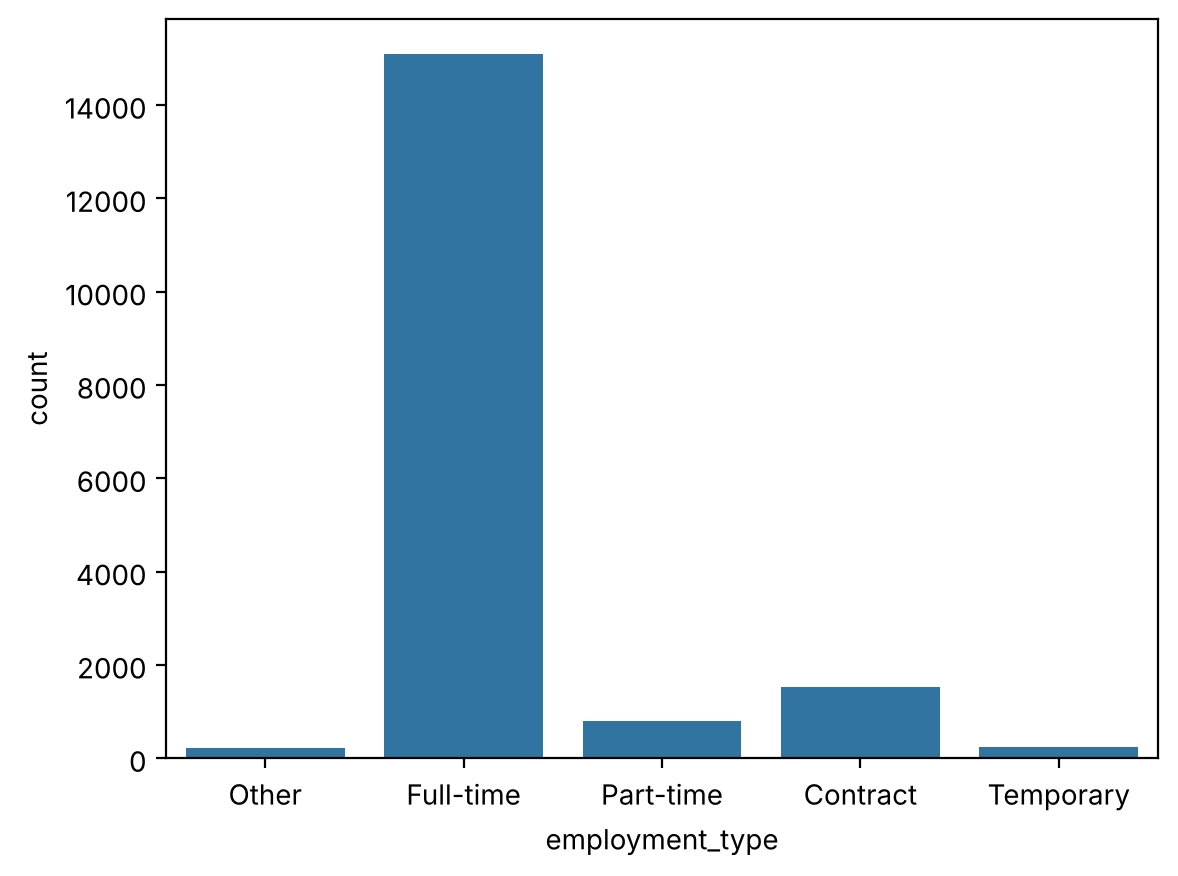

In [28]:
employment_type = df_jobs['employment_type']
sns.countplot(x=employment_type)

<Axes: xlabel='has_company_logo', ylabel='count'>

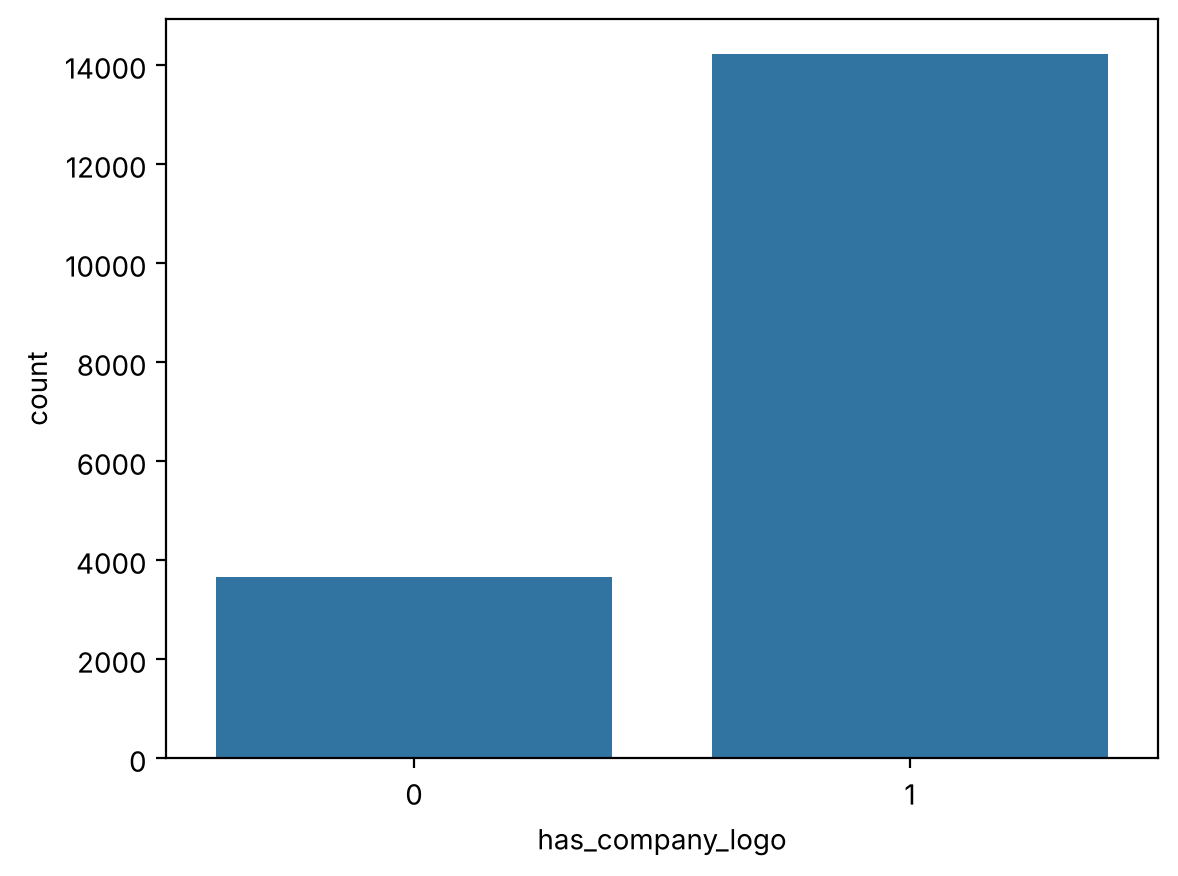

In [29]:
title = df_jobs['has_company_logo']
sns.countplot(x=title)

### Fraud Rates

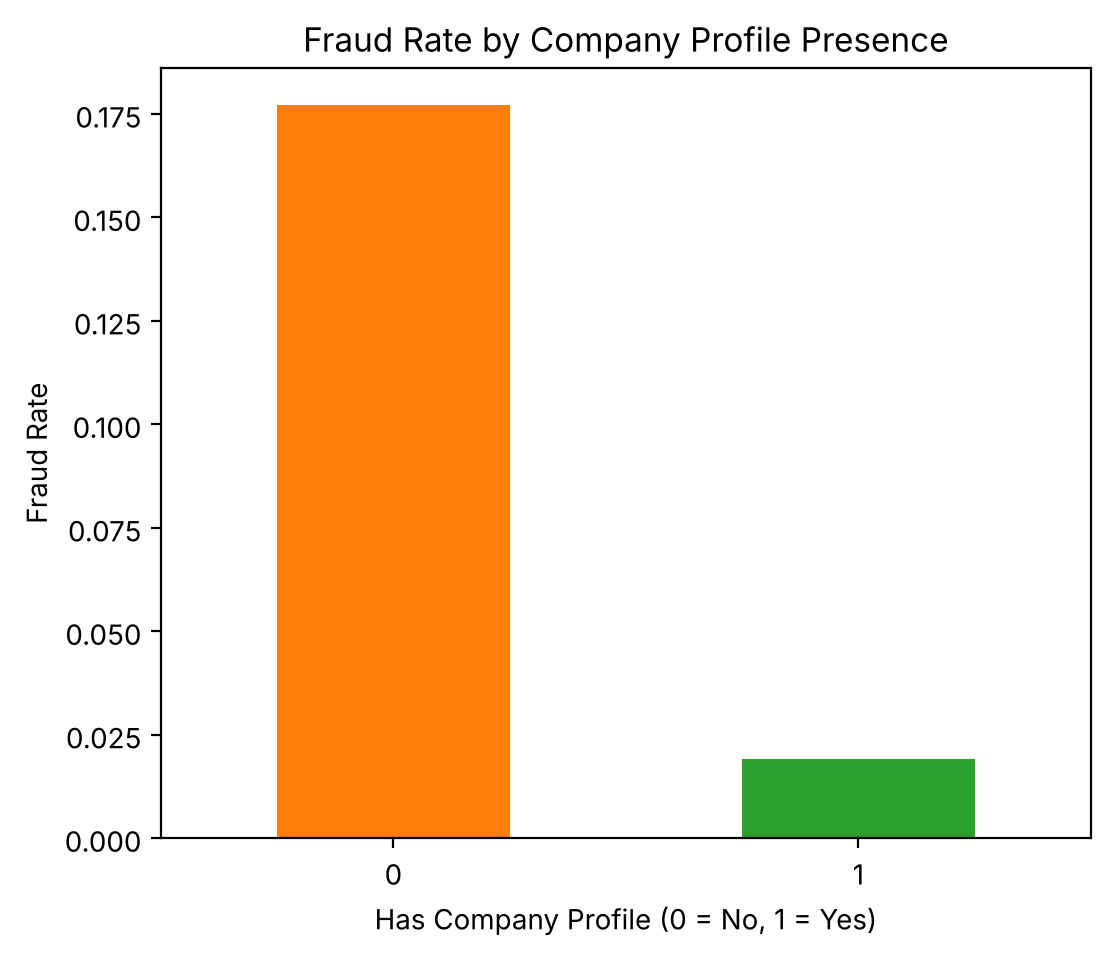

In [30]:
plt.figure(figsize=(6,5))
fraud_rate_by_profile = df_jobs.groupby('has_company_profile')['fraudulent'].mean()
fraud_rate_by_profile.plot(kind='bar',color=['tab:orange','tab:green'])
plt.title('Fraud Rate by Company Profile Presence')
plt.xlabel('Has Company Profile (0 = No, 1 = Yes)')
plt.ylabel('Fraud Rate')
plt.xticks(rotation=0)
plt.show()

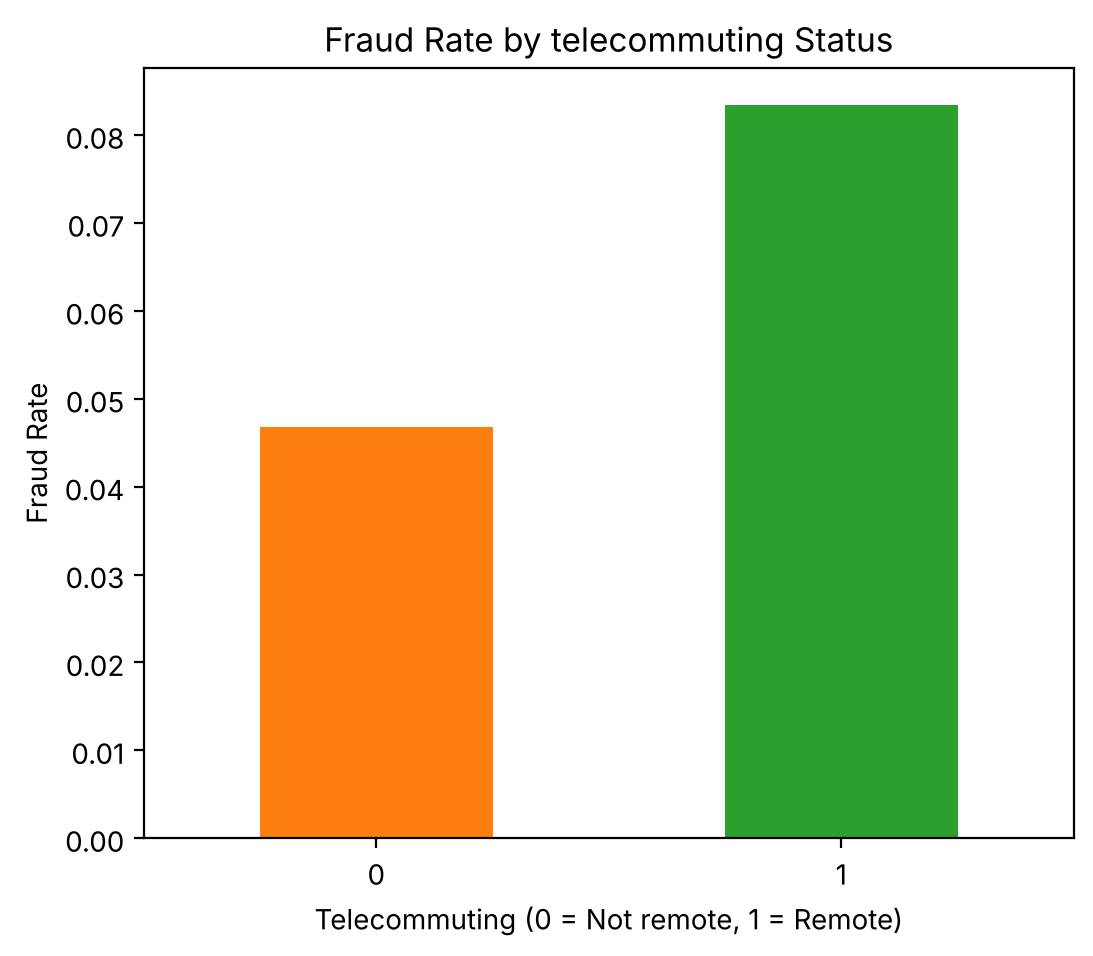

In [31]:
plt.figure(figsize=(6,5))
fraud_rate_by_profile = df_jobs.groupby('telecommuting')['fraudulent'].mean()
fraud_rate_by_profile.plot(kind='bar',color=['tab:orange','tab:green'])
plt.title('Fraud Rate by telecommuting Status')
plt.xlabel('Telecommuting (0 = Not remote, 1 = Remote)')
plt.ylabel('Fraud Rate')
plt.xticks(rotation=0)
plt.show()

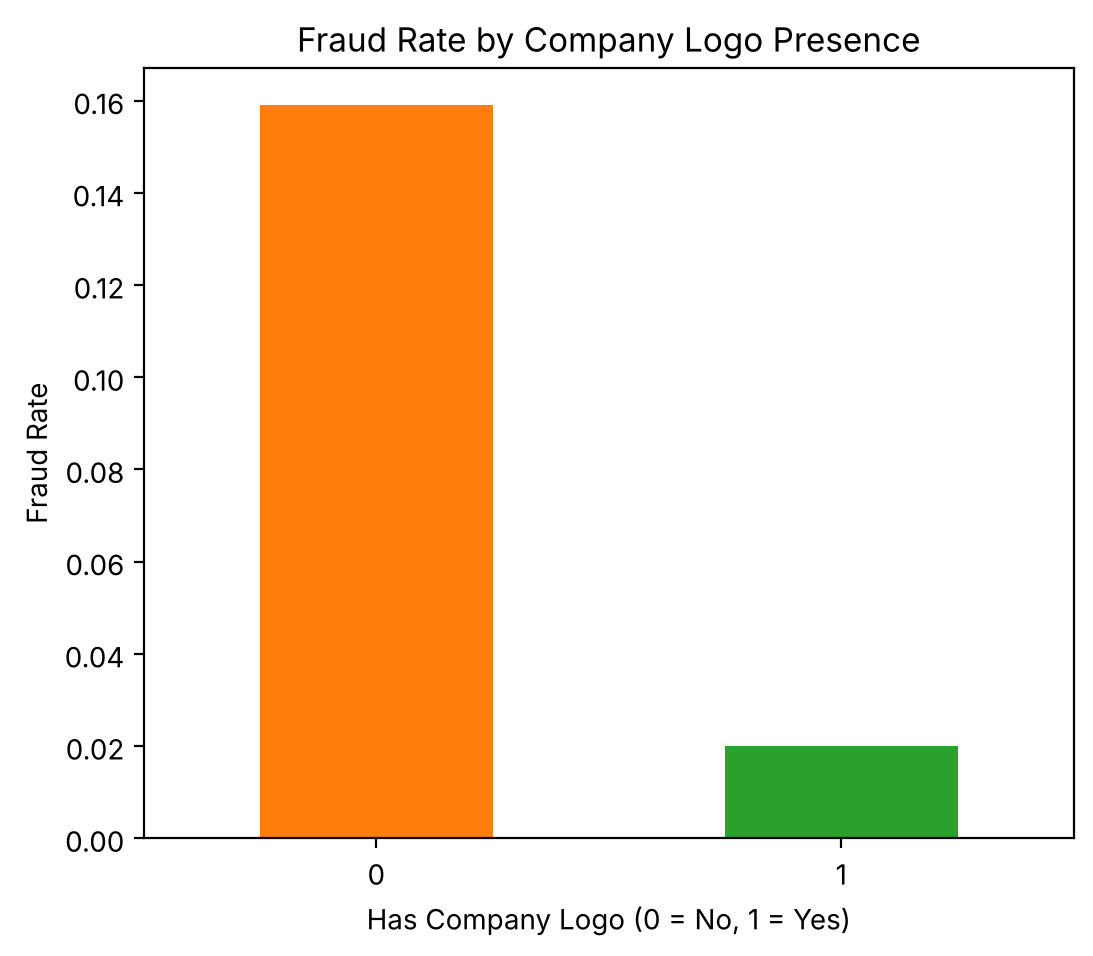

In [32]:
plt.figure(figsize=(6,5))
fraud_rate_by_profile = df_jobs.groupby('has_company_logo')['fraudulent'].mean()
fraud_rate_by_profile.plot(kind='bar',color=['tab:orange','tab:green'])
plt.title('Fraud Rate by Company Logo Presence')
plt.xlabel('Has Company Logo (0 = No, 1 = Yes)')
plt.ylabel('Fraud Rate')
plt.xticks(rotation=0)
plt.show()

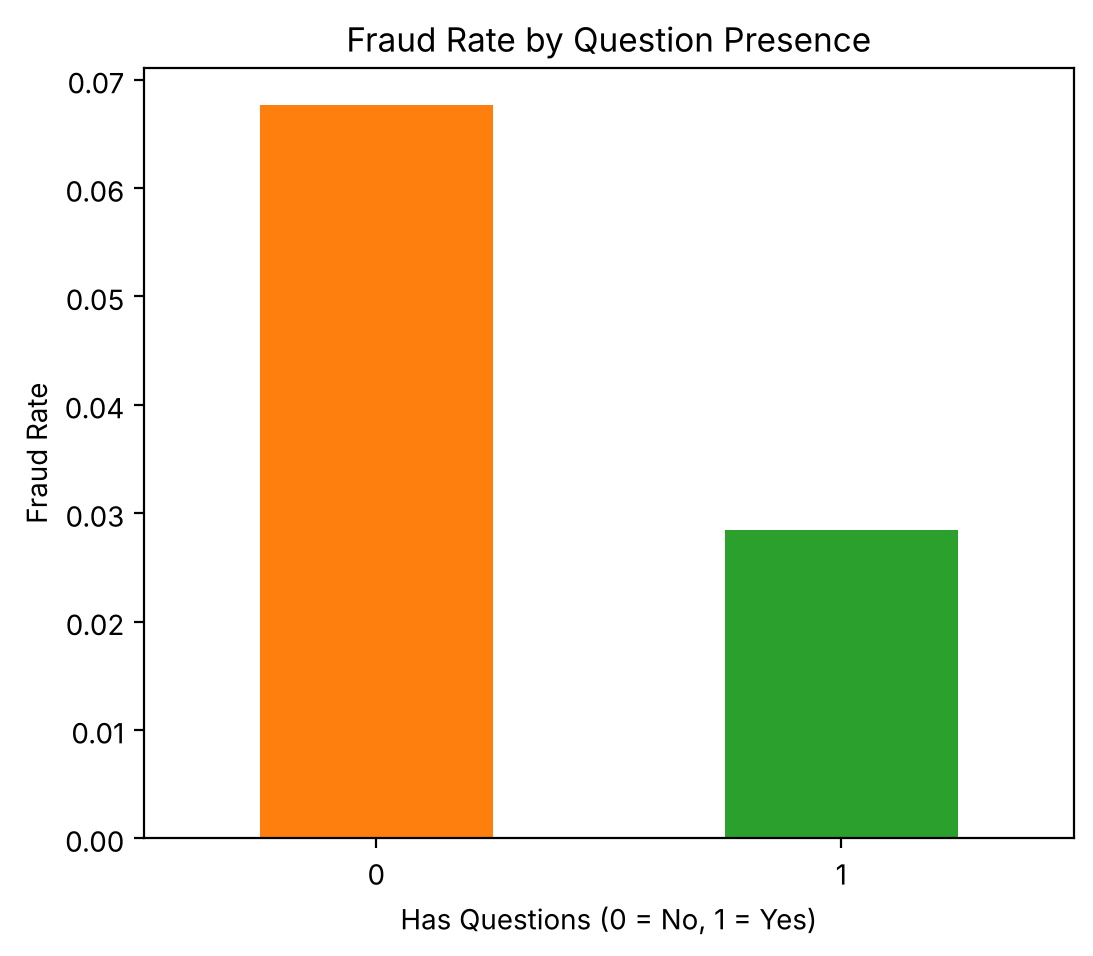

In [33]:
plt.figure(figsize=(6,5))
fraud_rate_by_profile = df_jobs.groupby('has_questions')['fraudulent'].mean()
fraud_rate_by_profile.plot(kind='bar',color=['tab:orange','tab:green'])
plt.title('Fraud Rate by Question Presence')
plt.xlabel('Has Questions (0 = No, 1 = Yes)')
plt.ylabel('Fraud Rate')
plt.xticks(rotation=0)
plt.show()

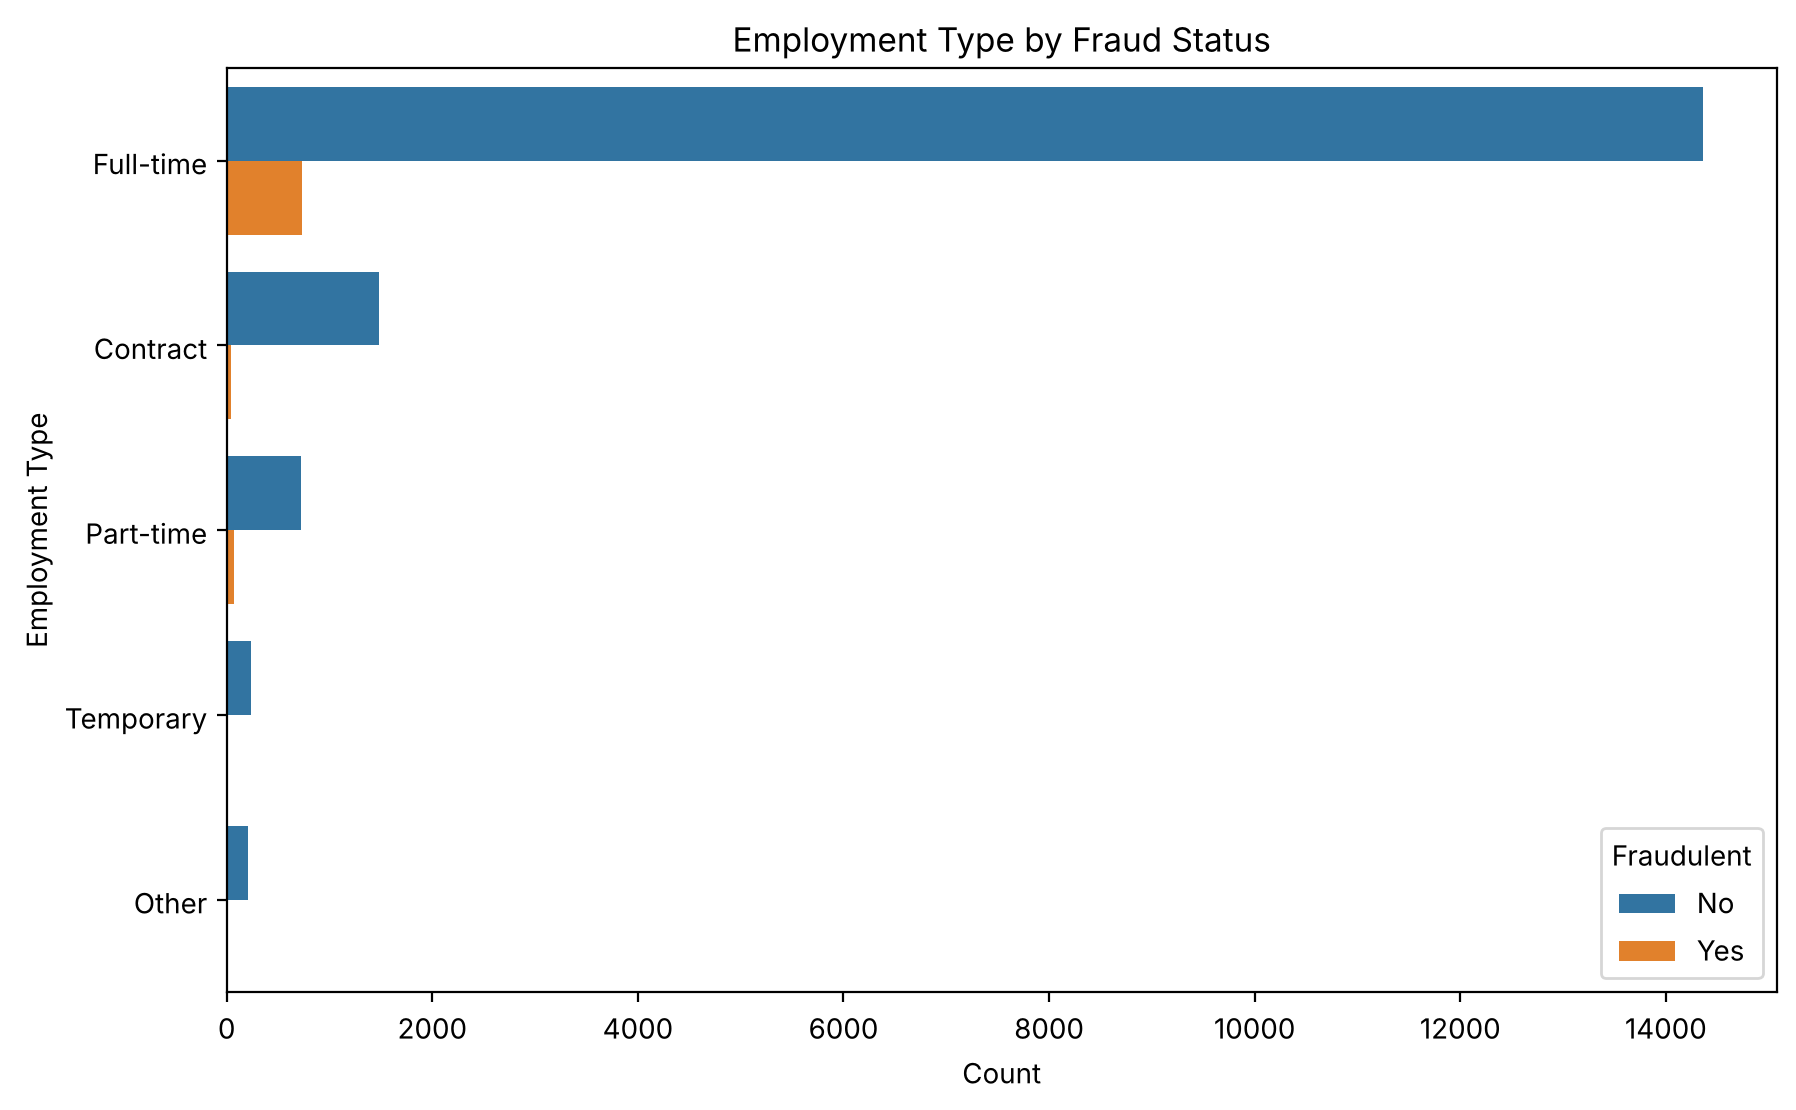

In [34]:
plt.figure(figsize=(10,6))
sns.countplot(data=df_jobs, y='employment_type', hue='fraudulent',
              order=df_jobs['employment_type'].value_counts().index)
plt.title('Employment Type by Fraud Status')
plt.xlabel('Count')
plt.ylabel('Employment Type')
plt.legend(title='Fraudulent', labels=['No', 'Yes'])
plt.show()

### Employment Type Pie Chart

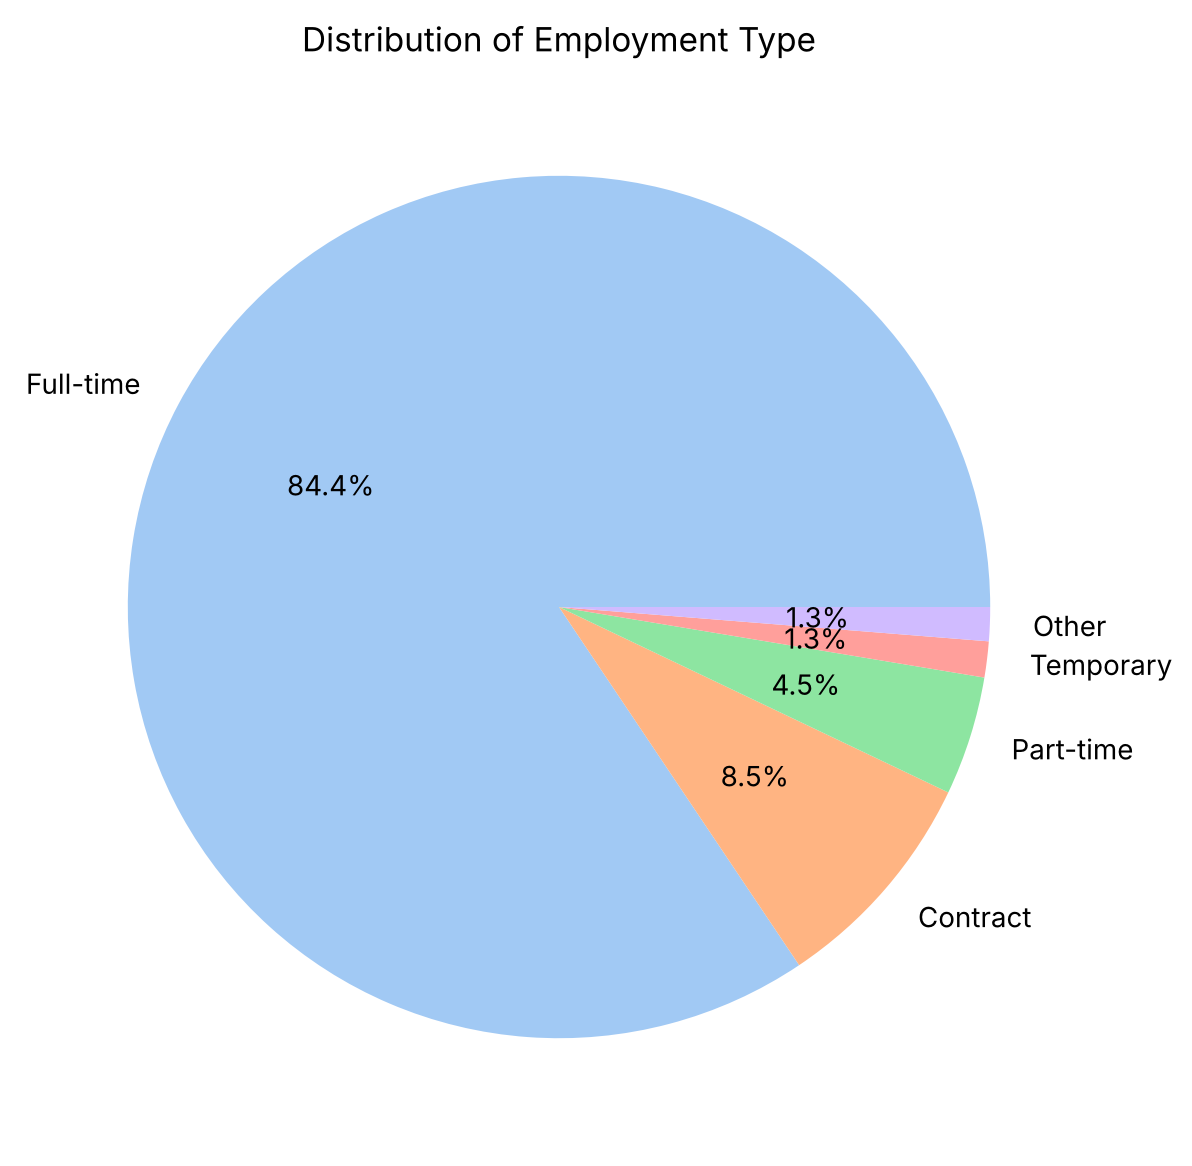

In [35]:
plt.figure(figsize=(7,7))
counts=df_jobs['employment_type'].value_counts()
colors = sns.color_palette('pastel',len(counts))
counts.plot(kind='pie',autopct='%1.1f%%',colors=colors)
plt.title('Distribution of Employment Type')
plt.ylabel('')
plt.show()

### String Length Distribution

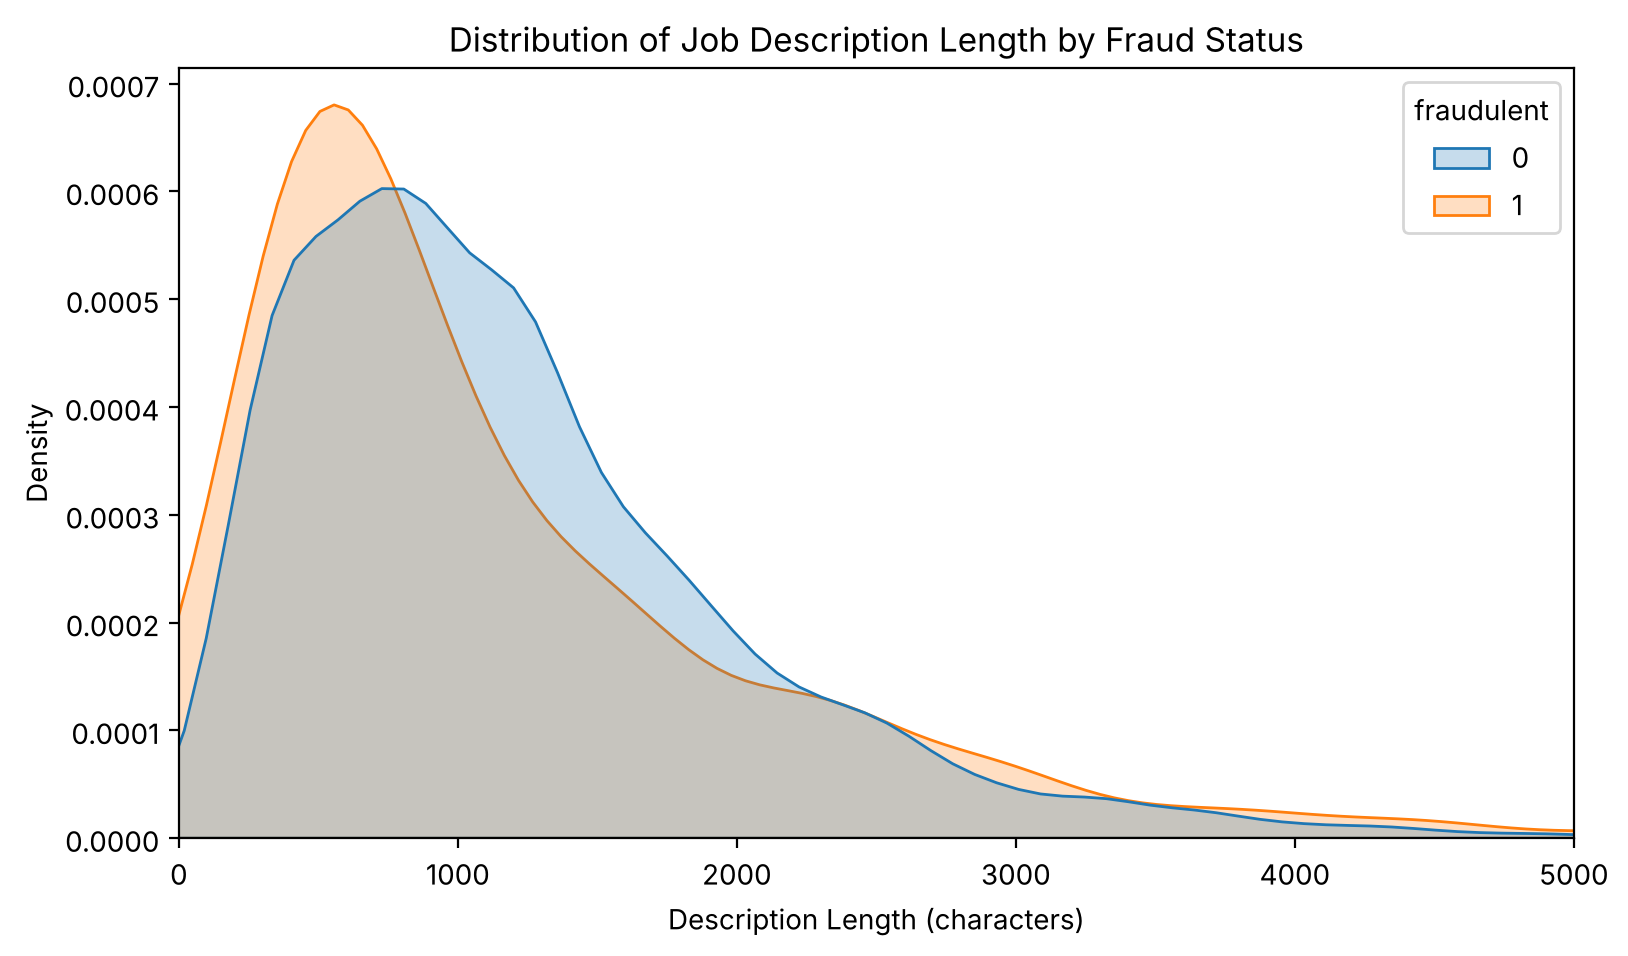

In [36]:
df_jobs['description_length'] = df_jobs['description'].str.len()

plt.figure(figsize=(9,5))
sns.kdeplot(data=df_jobs, x='description_length',hue='fraudulent', fill=True, common_norm=False)
plt.title('Distribution of Job Description Length by Fraud Status')
plt.xlabel('Description Length (characters)')
plt.xlim(0,5000)
plt.show()

#### Fraud Rate By Location

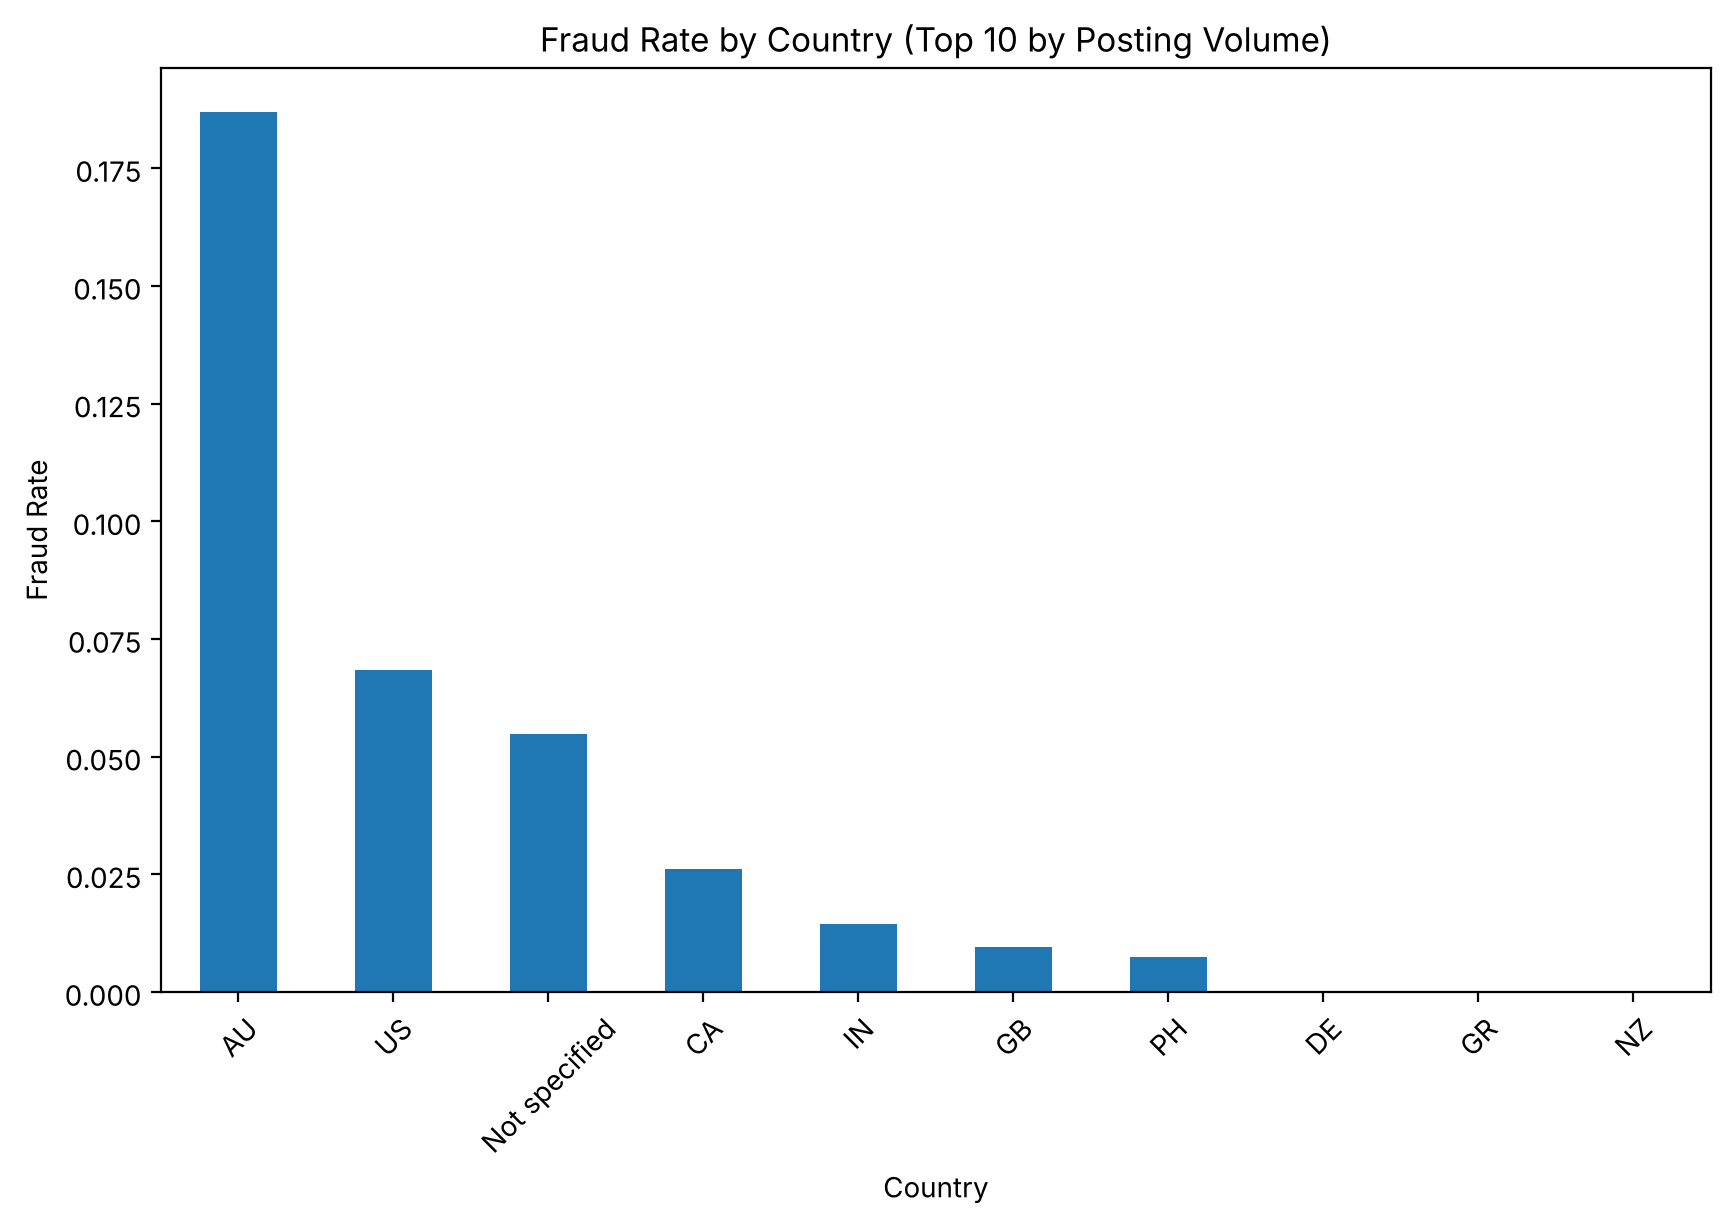

In [37]:
df_jobs['country']=df_jobs['location'].str.split(',').str[0]

top_countries = df_jobs['country'].value_counts().head(10).index

plt.figure(figsize=(10,6))
fraud_by_country = df_jobs[df_jobs['country'].isin(top_countries)].groupby(['country'])['fraudulent'].mean().sort_values(ascending=False)
fraud_by_country.plot(kind='bar', color='tab:blue')
plt.title('Fraud Rate by Country (Top 10 by Posting Volume)')
plt.xlabel('Country')
plt.ylabel('Fraud Rate')
plt.xticks(rotation=45)
plt.show()


# Descriptive Statistics of the Wrangled Data

### Numeric Stats

In [38]:
df_jobs.describe()

,job_id,telecommuting,has_company_logo,has_questions,fraudulent,has_company_profile,description_length
count,17879.000000,17879.000000,17879.000000,17879.000000,17879.000000,17879.000000,17879.000000
mean,8940.020471,0.042899,0.795346,0.491750,0.048381,0.815034,1218.072543
std,5161.401801,0.202636,0.403459,0.499946,0.214576,0.388281,894.807276
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000
25%,4470.500000,0.000000,1.000000,0.000000,0.000000,1.000000,607.000000
50%,8940.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1017.000000
75%,13409.500000,0.000000,1.000000,1.000000,0.000000,1.000000,1586.000000
max,17880.000000,1.000000,1.000000,1.000000,1.000000,1.000000,14907.000000


### Categorical Stats

In [39]:
df_jobs[['title','employment_type','location','company_profile','description', 'requirements']].describe()

,title,employment_type,location,company_profile,description,requirements
count,17879,17879,17879,17879,17879,17879
unique,11231,5,3106,1710,14801,11968
top,English Teacher Abroad,Full-time,"GB, LND, London",No profile provided,"Play with kids, get paid for it Love travel? J...",No requirements specified
freq,311,15090,718,3307,379,2695


In [40]:
fraud_counts = df_jobs['fraudulent'].value_counts()
fraud_pct=df_jobs['fraudulent'].value_counts(normalize=True) *100

pd.DataFrame({'count':fraud_counts,'percentage':fraud_pct.round(2)})

,count,percentage
fraudulent,,
0,17014,95.16
1,865,4.84


# Conclusion

The data is fairly clean, with little to no need for binning or column changes for this initial narrative.  Still, many columns had a high occurrence of missing entries. The target variable for this dataset is fraudulent, a binary column that indicates whether a job posting is fraudulent. Only 4.84% of postings in this dataset are labeled as fraudulent. There are several binary columns, including has_company_logo, has_questions, telecommuting, and the engineered has_company_profile, flag--proved useful in identifying patterns associated with fraudulent postings. As shown in the Statistical Data Visualization section, postings missing a company profile or company logo had a substantially higher fraud rate than postings that included them, suggesting the absence of verifiable company information is one of the strongest indicators of a fraudulent listing in this dataset. Description length also showed a modest relationship with fraud status: fraudulent postings tended to have shorter descriptions (median 846 characters vs. 1,027 for legitimate postings). Other key findings included a notably high fraud rate associated with postings located in Australia. Overall, these findings suggest company profile presence, logo presence, employment type, location, and description length carry disproportionate signal for identifying fraudulent postings, despite fraud representing a small overall share of the dataset. 